# 02. Standalone Dataset Feature Extraction & Space Analysis

**Research Project:** *Comparative Analysis of CNN, RNN, and Hybrid CNN–RNN Architectures for Papilledema Detection and Severity Grading*

> **Notebook Role (Presentation Only):** All handcrafted feature extraction, CNN penultimate embedding extraction, dimensionality reduction, correlation computation, and leak-free ML baseline training live externally in `src/feature_extraction/` (`scripts/extract_features.py`). This notebook presents the saved CSVs, NPZ summaries, and PNG/PDF figures.

## 1. Distinction Between Internal Classification Features and Standalone Extraction

This phase explicitly distinguishes three feature sources:
1. **Handcrafted Image Features:** Scalar intensity, RGB colour (Fundus only), multi-distance GLCM texture, uniform LBP histograms/entropy, HOG gradient structure, and edge/center-vs-periphery statistics extracted directly from raw-standardized images (`86` scalar features + `1296`-d HOG for Fundus; `48` scalar features + `1296`-d HOG for OCT).
2. **Standalone Deep Embeddings:** Global-average-pooled penultimate feature vectors exported directly from trained `seed42` CNN checkpoints (`ResNet50`: `2048-d`, `DenseNet121`: `1024-d`, `EfficientNet-B0`: `1280-d`).
3. **Keep Modalities Separate:** Fundus (`N=1,367`), Individual OCT (`N=1,140`), and Exploratory OCT Severity (`N=895`) are analyzed strictly independently.

> **Exploratory Disclosure:** Full-dataset PCA/t-SNE/UMAP plots are *unsupervised exploratory visualizations* (with held-out test samples overlaid as triangles and deep checkpoints trained on the original `seed42` train split). All supervised feature-based classifier benchmarks (`LogisticRegression`, `RandomForest`) fit standardization and classifiers **strictly inside each training fold**.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

FEAT_DIR = Path("../results/feature_extraction") if Path("../results/feature_extraction").exists() else Path("results/feature_extraction")
FIG_DIR = FEAT_DIR / "figures"
manifest = json.loads((FEAT_DIR / "feature_extraction_manifest.json").read_text(encoding="utf-8"))
print(f"Fundus scalar dim={manifest['fundus_handcrafted_dim']} (HOG={manifest['fundus_hog_dim']}) | OCT scalar dim={manifest['oct_handcrafted_dim']} (HOG={manifest['oct_hog_dim']})")

Fundus scalar dim=86 (HOG=1296) | OCT scalar dim=48 (HOG=1296)


## 2. Handcrafted Feature Summary (Intensity, RGB, Texture, Structural & HOG)

In [2]:
f_hc = pd.read_csv(FEAT_DIR / "fundus_handcrafted_features.csv")
o_hc = pd.read_csv(FEAT_DIR / "oct_handcrafted_features.csv")
print(f"Loaded Fundus handcrafted table: {f_hc.shape} | OCT handcrafted table: {o_hc.shape}")
display(f_hc.groupby("label")[["int_mean", "rgb_rg_ratio", "glcm_homogeneity_d3", "lbp_entropy", "edge_sobel_mean", "struct_center_periph_ratio"]].agg(["mean", "std"]).round(3))
display(o_hc.groupby("label")[["int_mean", "glcm_contrast_d1", "lbp_entropy", "hog_max", "edge_canny_density", "struct_center_periph_ratio"]].agg(["mean", "std"]).round(3))

Loaded Fundus handcrafted table: (1367, 91) | OCT handcrafted table: (1140, 55)


int_mean         rgb_rg_ratio        glcm_homogeneity_d3  \
                      mean     std         mean    std                mean   
label                                                                        
Normal             127.541  15.631        1.571  0.157               0.717   
Papilledema        107.606  27.319        1.805  0.279               0.820   
Pseudopapilledema  112.225  17.919        1.660  0.129               0.736   

                         lbp_entropy        edge_sobel_mean         \
                     std        mean    std            mean    std   
label                                                                
Normal             0.035       3.068  0.085          23.462  3.717   
Papilledema        0.036       3.104  0.059          14.067  3.069   
Pseudopapilledema  0.037       3.107  0.070          21.169  3.462   

                  struct_center_periph_ratio         
                                        mean    std  
label                                                
Normal                                 1.396  0.177  
Papilledema                            1.304  0.174  
Pseudopapilledema                      1.322  0.120

int_mean         glcm_contrast_d1        lbp_entropy         \
                      mean     std             mean    std        mean    std   
label                                                                           
Normal              40.298   6.967            5.429  1.465       2.944  0.158   
Papilledema         48.388  13.209            6.809  2.522       3.020  0.165   
Pseudopapilledema   45.076   6.476            6.913  2.012       2.971  0.225   

                  hog_max        edge_canny_density         \
                     mean    std               mean    std   
label                                                        
Normal              0.391  0.078              0.196  0.037   
Papilledema         0.346  0.060              0.236  0.052   
Pseudopapilledema   0.437  0.147              0.231  0.033   

                  struct_center_periph_ratio         
                                        mean    std  
label                                                
Normal                                 1.955  0.416  
Papilledema                            1.861  0.482  
Pseudopapilledema                      1.561  0.528

## 3. Standalone Deep CNN Embedding Inventory

All `9` deep embedding matrices were extracted using verified existing `seed42` `best.pt` checkpoints (`checkpoint_loaded=True`) without retraining extra CNNs.

In [3]:
deep_tbl = pd.read_csv(FEAT_DIR / "deep_extraction_summary.csv")
display(deep_tbl.round(3))

,track,modality,backbone,embedding_dim,n_samples,checkpoint_loaded,checkpoint_path,l2_norm_mean,l2_norm_std
0,fundus_3class,fundus,resnet50,2048,1367,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,23.974,9.857
1,fundus_3class,fundus,densenet121,1024,1367,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,28.988,6.537
2,fundus_3class,fundus,efficientnet_b0,1280,1367,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,19.026,5.165
3,oct_individual,oct,resnet50,2048,1140,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,22.544,6.645
4,oct_individual,oct,densenet121,1024,1140,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,33.211,5.915
5,oct_individual,oct,efficientnet_b0,1280,1140,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,15.757,4.868
6,oct_severity,oct,resnet50,2048,895,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,24.249,8.022
7,oct_severity,oct,densenet121,1024,895,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,26.893,6.379
8,oct_severity,oct,efficientnet_b0,1280,895,True,C:\Users\Shuvendu\Desktop\Papilledema_analysis...,17.009,5.414


## 4. Class-Wise Handcrafted Feature Distributions

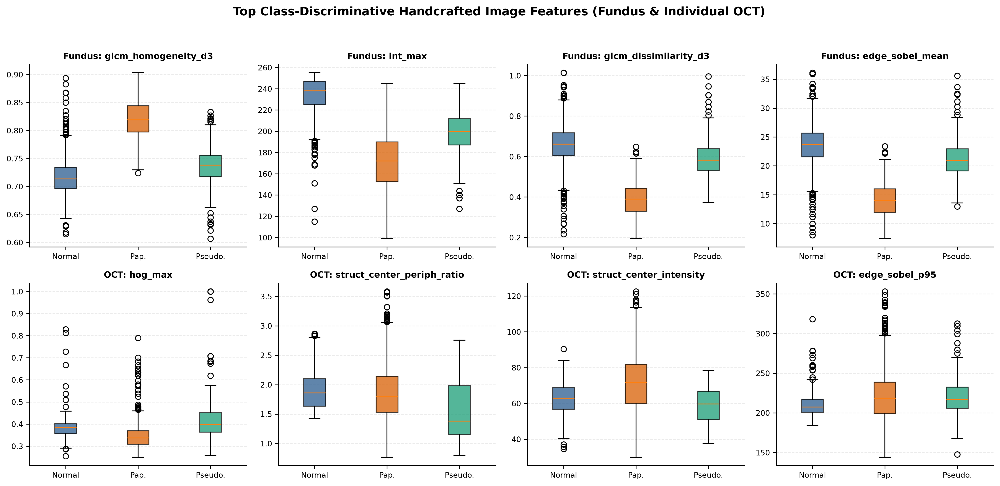

In [4]:
display(Image(filename=str(FIG_DIR / "fig01_handcrafted_feature_distributions.png")))

## 5. Handcrafted Feature Correlation Heatmaps

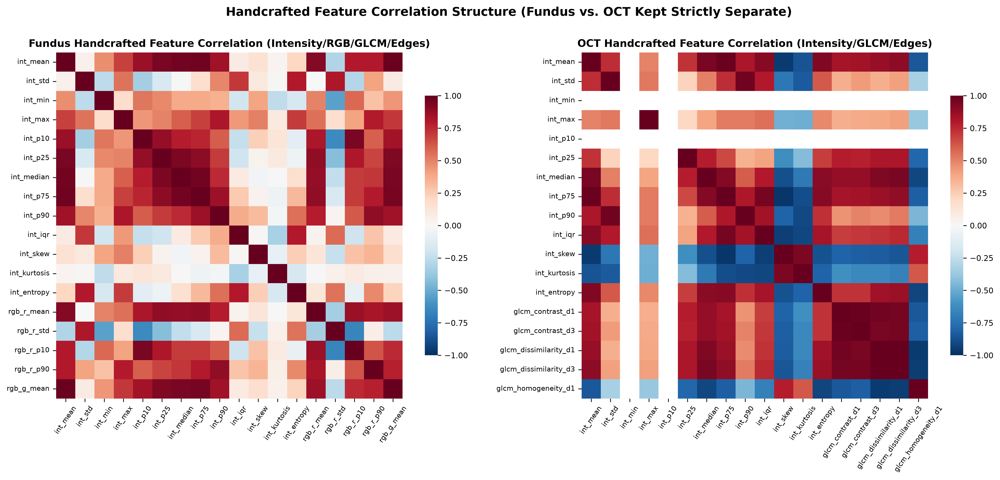

In [5]:
display(Image(filename=str(FIG_DIR / "fig02_handcrafted_correlation_heatmap.png")))

## 6. PCA Explained Variance Comparison

Deep CNN representations concentrate diagnostic variance into far fewer principal directions than raw handcrafted features (`EfficientNet-B0` and `ResNet50` capture high variance rapidly).

n_components                       2      10     25     50
track          feature_space                              
fundus_3class  densenet121      0.480  0.638  0.730  0.797
               efficientnet_b0  0.605  0.709  0.780  0.834
               handcrafted      0.506  0.852  0.963  0.999
               resnet50         0.586  0.690  0.753  0.803
oct_individual densenet121      0.251  0.521  0.655  0.743
               efficientnet_b0  0.327  0.519  0.638  0.729
               handcrafted      0.774  0.982  0.999    NaN
               resnet50         0.537  0.710  0.794  0.844
oct_severity   densenet121      0.390  0.721  0.811  0.867
               efficientnet_b0  0.447  0.716  0.800  0.857
               handcrafted      0.785  0.983  0.999    NaN
               resnet50         0.449  0.758  0.827  0.870

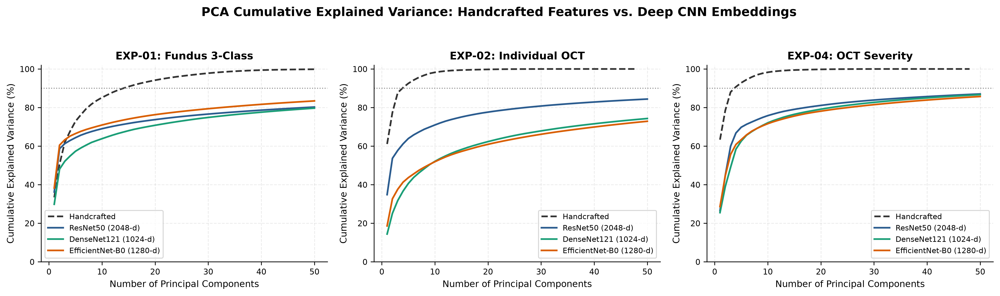

In [6]:
pca_var = pd.read_csv(FEAT_DIR / "pca_variance_explained.csv")
display(pca_var[pca_var["n_components"].isin([2, 10, 25, 50])].pivot(index=["track", "feature_space"], columns="n_components", values="cum_explained_variance").round(3))
display(Image(filename=str(FIG_DIR / "fig03_pca_scree_variance.png")))

## 7. Fundus 2D Feature Space Projections (PCA, t-SNE, UMAP — Exploratory)

Notice `Normal` Fundus exhibits two natural acquisition sub-clusters, while `Papilledema` and `Pseudopapilledema` overlap noticeably in handcrafted space (`OOF Macro-F1 = 0.877`) before separating cleanly in CNN embedding manifolds.

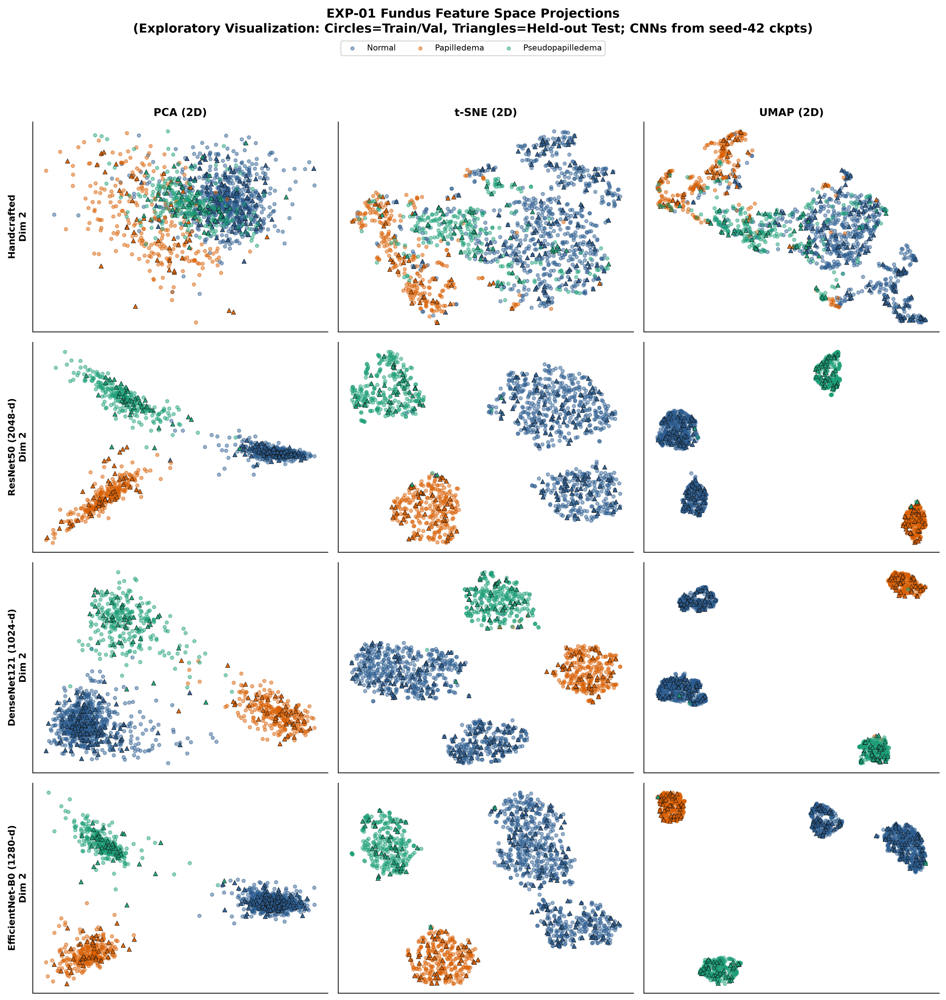

In [7]:
display(Image(filename=str(FIG_DIR / "fig04_fundus_feature_space_2d.png")))

## 8. Individual OCT 2D Feature Space Projections (PCA, t-SNE, UMAP — Exploratory)

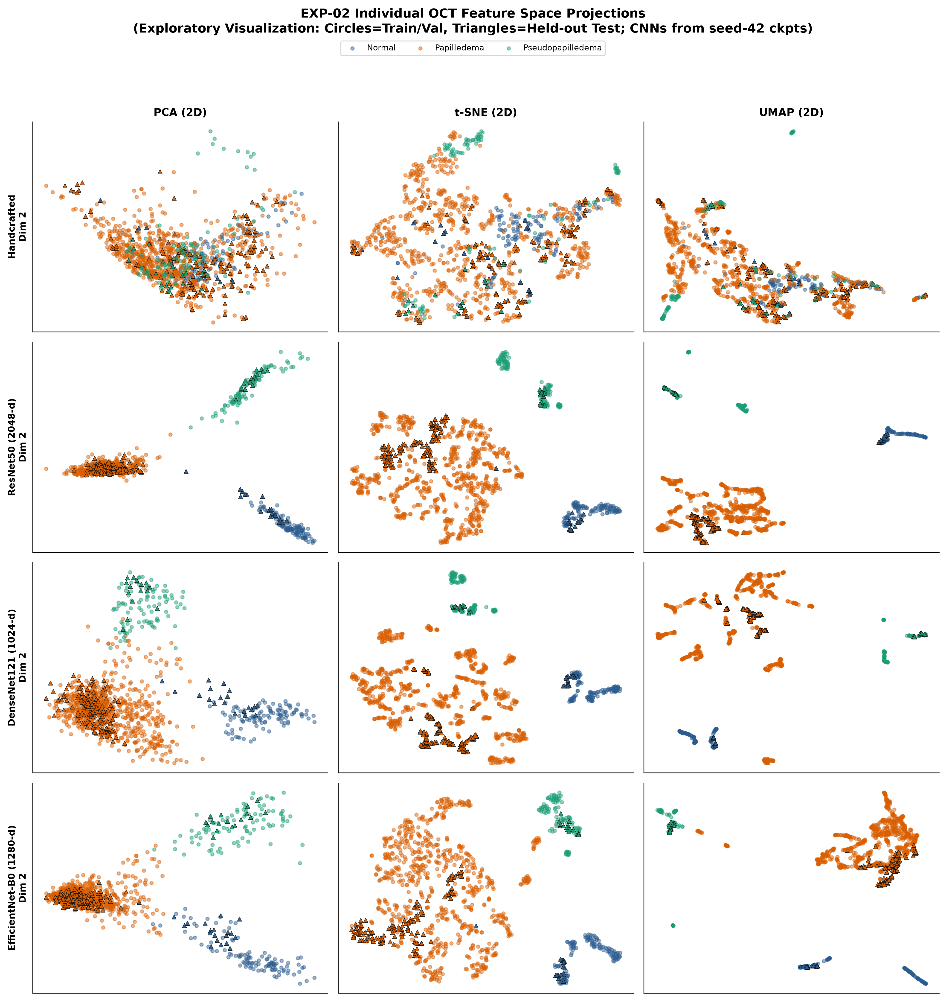

In [8]:
display(Image(filename=str(FIG_DIR / "fig05_oct_feature_space_2d.png")))

## 9. OCT Severity Exploratory Feature Space (G1–G4 Folder-Derived Labels)

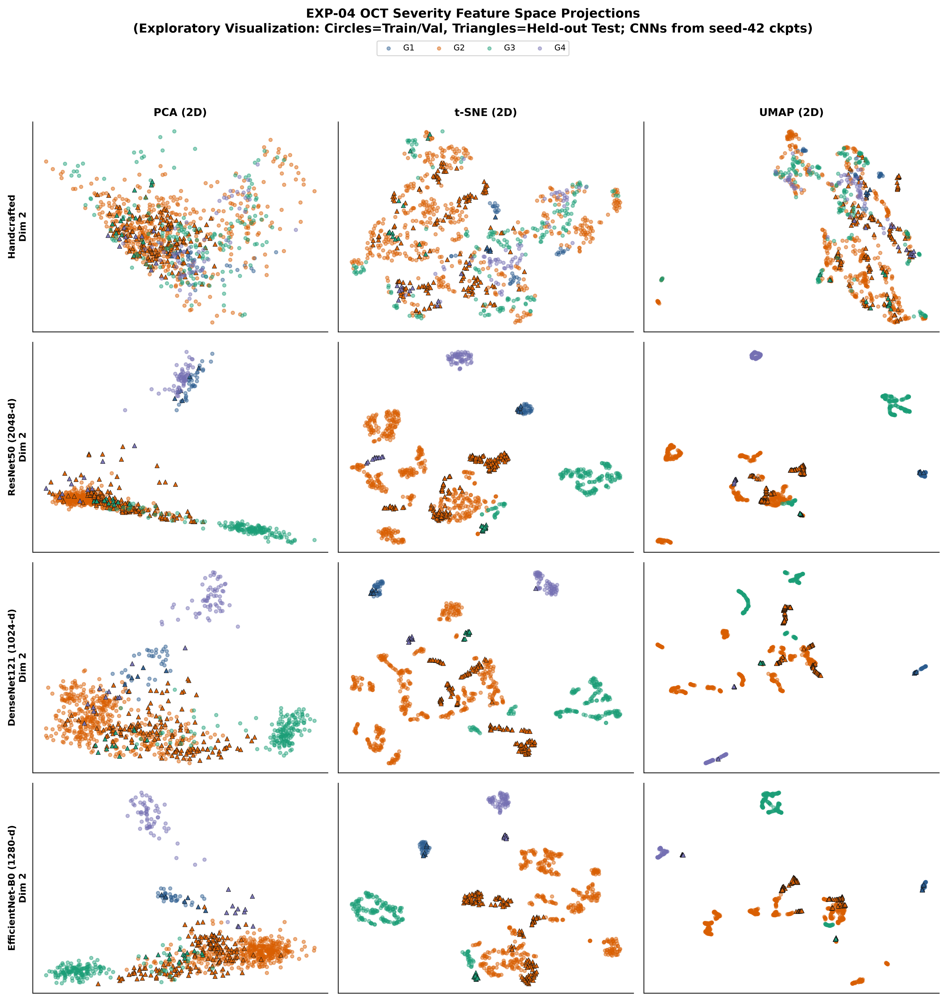

In [9]:
display(Image(filename=str(FIG_DIR / "fig06_oct_severity_feature_space_2d.png")))

## 10. Leak-Free Handcrafted ML Baseline & Feature Importance

All standardization (`StandardScaler`) and model fitting were restricted strictly to each training fold (`5-fold StratifiedGroupKFold` on Fundus; `contiguous slice-block + prefix balanced 5-fold` on OCT, explicitly NOT patient-independent).

,track,feature_set,classifier,cv_scheme,mean_fold_macro_f1,std_fold_macro_f1,oof_macro_f1,oof_accuracy,oof_balanced_accuracy
0,fundus_3class,Handcrafted (86 scalar features),LogisticRegression,StratifiedGroupKFold (cluster_id),0.8761,0.0196,0.8767,0.8939,0.8886
1,fundus_3class,Handcrafted (86 scalar features),RandomForest,StratifiedGroupKFold (cluster_id),0.8638,0.0128,0.8644,0.8837,0.8741
2,oct_individual,Handcrafted (48 scalar features),LogisticRegression,Contiguous Slice-Block + Prefix Balanced 5-Fol...,0.6207,0.0591,0.6196,0.7509,0.7090
3,oct_individual,Handcrafted (48 scalar features),RandomForest,Contiguous Slice-Block + Prefix Balanced 5-Fol...,0.5657,0.0568,0.5675,0.7439,0.5773
4,oct_severity,Handcrafted (48 scalar features),LogisticRegression,Contiguous Slice-Block + Prefix Balanced 5-Fol...,0.6438,0.1666,0.6114,0.6547,0.7260
5,oct_severity,Handcrafted (48 scalar features),RandomForest,Contiguous Slice-Block + Prefix Balanced 5-Fol...,0.5192,0.2132,0.5106,0.5531,0.5556


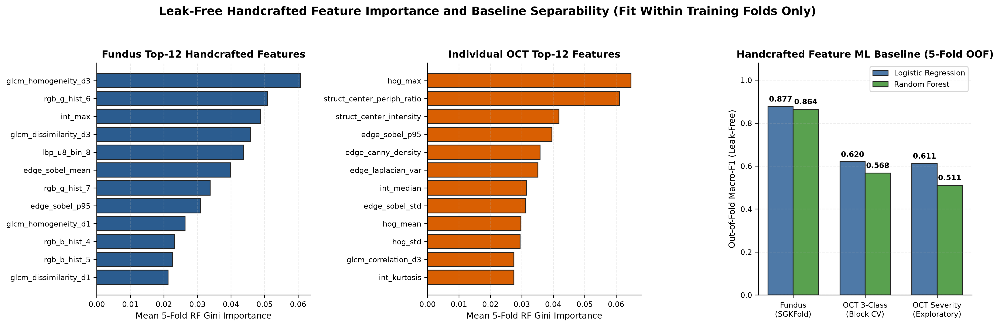

Top 5 features — fundus_3class:


,track,feature,rf_mean_importance,kruskal_h,kruskal_p
0,fundus_3class,glcm_homogeneity_d3,0.0606,659.5342,0.0
1,fundus_3class,rgb_g_hist_6,0.0509,729.9010,0.0
2,fundus_3class,int_max,0.0488,816.0083,0.0
3,fundus_3class,glcm_dissimilarity_d3,0.0458,667.2939,0.0
4,fundus_3class,lbp_u8_bin_8,0.0437,623.5784,0.0


Top 5 features — oct_individual:


,track,feature,rf_mean_importance,kruskal_h,kruskal_p
0,oct_individual,hog_max,0.0648,154.1761,0.0000
1,oct_individual,struct_center_periph_ratio,0.0610,40.7617,0.0000
2,oct_individual,struct_center_intensity,0.0418,92.7173,0.0000
3,oct_individual,edge_sobel_p95,0.0396,11.7485,0.0028
4,oct_individual,edge_canny_density,0.0358,94.4641,0.0000


Top 5 features — oct_severity:


,track,feature,rf_mean_importance,kruskal_h,kruskal_p
0,oct_severity,hog_max,0.0735,100.6243,0.0
1,oct_severity,lbp_u8_bin_4,0.0536,182.5136,0.0
2,oct_severity,lbp_u8_bin_5,0.0445,137.3901,0.0
3,oct_severity,struct_center_periph_ratio,0.0423,84.7681,0.0
4,oct_severity,hog_mean,0.0387,46.3201,0.0


In [10]:
clf_df = pd.read_csv(FEAT_DIR / "handcrafted_ml_baseline_results.csv")
display(clf_df.round(4))
display(Image(filename=str(FIG_DIR / "fig07_feature_importance_and_rf_baseline.png")))
for trk in ("fundus_3class", "oct_individual", "oct_severity"):
    print(f"Top 5 features — {trk}:")
    display(pd.read_csv(FEAT_DIR / f"feature_importance_{trk}.csv").head(5).round(4))

## 11. Summary & Key Findings

1. **Handcrafted Separability:** Handcrafted GLCM, RGB, LBP, and structural features achieve solid baseline discrimination on Fundus (`OOF Macro-F1 = 0.877`, Logistic Regression) but struggle on OCT 3-class (`0.620`) and OCT Severity (`0.611`), highlighting why convolutional representation learning is essential for subtle retinal layer elevation.
2. **Deep vs. Handcrafted Geometry:** Across `ResNet50` (`2048-d`), `DenseNet121` (`1024-d`), and `EfficientNet-B0` (`1280-d`), `PCA`/`t-SNE`/`UMAP` confirm tighter class clustering and aligned held-out test manifolds on Fundus and OCT 3-class, while confirming heavy class overlap across exploratory `G1–G4` grades.
3. **Artifacts Exported:** Saved scalar CSVs (`fundus_handcrafted_features.csv`, `oct_handcrafted_features.csv`, `oct_severity_handcrafted_features.csv`), compressed NPZ caches (`*_handcrafted.npz`, `*_deep_embeddings.npz`), correlation matrices, DR coordinates, and leak-free feature importance tables.